In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)
sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("Insurance claims data.csv")

In [4]:
df.shape

(58592, 41)

In [5]:
df.head(3)

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,97.89bhp@3600rpm,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.9,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,POL007194,9.5,0.2,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


In [6]:
df.columns

Index(['policy_id', 'subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'segment', 'model', 'fuel_type',
       'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera',
       'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight',
       'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert',
       'ncap_rating', 'claim_status'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  object 
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  object 
 7   model                             58592 non-null  object 
 8   fuel_type                         58592 non-null  object 
 9   max_torque                        58592 non-null  object 
 10  max_power                         58592 non-null  object 
 11  engine_type                       58592 non-null  object 
 12  airb

In [8]:
df['claim_status'].value_counts()

claim_status
0    54844
1     3748
Name: count, dtype: int64

In [9]:
df.isna().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
(df['claim_status'].value_counts(normalize=True) * 100).round(2)

claim_status
0    93.6
1     6.4
Name: proportion, dtype: float64

We call a heavy imbalanced classification problem. It means a lazy model

could just predict no claim for every single policy still be right 93.6% of 

the time while being completely useless in practise. So later on when we 

train our model we cannot just look at accuracy. We are going to need 

metrics like recall precision and we may need to handle this imbalance data set



### Split the column into numerical and categorical groups

In [12]:
num_cols = df.select_dtypes(include = ["int64", "float64"]).columns.to_list()

len(num_cols)                            

13

In [13]:
obj_cols = df.select_dtypes(include = "object").columns.to_list()
len(obj_cols)

28

In [14]:
df.head(2)

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,97.89bhp@3600rpm,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.9,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0


#### We are going to remove policy_id and claim_status

In [15]:
num_cols.remove("claim_status")
obj_cols.remove("policy_id")

##### we want to know how many unique values in each categorical columns

In [16]:
for col in obj_cols:
    
    uniques = df[col].unique()
    print(f"{col:35s} - unique values: {df[col].nunique():3d} - sample: {uniques[:5]}")
    

region_code                         - unique values:  22 - sample: ['C8' 'C2' 'C10' 'C13' 'C7']
segment                             - unique values:   6 - sample: ['C2' 'C1' 'A' 'B2' 'B1']
model                               - unique values:  11 - sample: ['M4' 'M9' 'M1' 'M5' 'M7']
fuel_type                           - unique values:   3 - sample: ['Diesel' 'CNG' 'Petrol']
max_torque                          - unique values:   9 - sample: ['250Nm@2750rpm' '200Nm@1750rpm' '60Nm@3500rpm' '200Nm@3000rpm'
 '113Nm@4400rpm']
max_power                           - unique values:   9 - sample: ['113.45bhp@4000rpm' '97.89bhp@3600rpm' '40.36bhp@6000rpm'
 '88.77bhp@4000rpm' '88.50bhp@6000rpm']
engine_type                         - unique values:  11 - sample: ['1.5 L U2 CRDi' 'i-DTEC' 'F8D Petrol Engine' '1.5 Turbocharged Revotorq'
 '1.2 L K Series Engine']
is_esc                              - unique values:   2 - sample: ['Yes' 'No']
is_adjustable_steering              - unique values:   2 - sam

In [17]:
binary_cols = [c for c in obj_cols if set(df[c].unique()) <={"Yes", "No"}]

# set is for set of iteration
# return us the columns which contain the values Yes and No            

In [18]:
binary_cols

['is_esc',
 'is_adjustable_steering',
 'is_tpms',
 'is_parking_sensors',
 'is_parking_camera',
 'is_front_fog_lights',
 'is_rear_window_wiper',
 'is_rear_window_washer',
 'is_rear_window_defogger',
 'is_brake_assist',
 'is_power_door_locks',
 'is_central_locking',
 'is_power_steering',
 'is_driver_seat_height_adjustable',
 'is_day_night_rear_view_mirror',
 'is_ecw',
 'is_speed_alert']

In [19]:
results = []

for col in binary_cols:
    rates = df.groupby(col)["claim_status"].mean() * 100
    gap = abs(rates.get("Yes", 0) - rates.get("No", 0))
    results.append((col, rates.get("No", np.nan), rates.get("Yes", np.nan), gap))

In [20]:
results

[('is_esc',
  np.float64(6.347192157448185),
  np.float64(6.5050812455844795),
  np.float64(0.15788908813629465)),
 ('is_adjustable_steering',
  np.float64(5.97416110292205),
  np.float64(6.671170410403649),
  np.float64(0.6970093074815988)),
 ('is_tpms',
  np.float64(6.38713151164356),
  np.float64(6.42745042088743),
  np.float64(0.04031890924387049)),
 ('is_parking_sensors',
  np.float64(5.39401601348504),
  np.float64(6.439104217435386),
  np.float64(1.0450882039503453)),
 ('is_parking_camera',
  np.float64(6.413847187990142),
  np.float64(6.370150297098917),
  np.float64(0.043696890891225415)),
 ('is_front_fog_lights',
  np.float64(6.057411612066169),
  np.float64(6.643480311247347),
  np.float64(0.5860686991811779)),
 ('is_rear_window_wiper',
  np.float64(6.355382619974059),
  np.float64(6.49840783111216),
  np.float64(0.14302521113810052)),
 ('is_rear_window_washer',
  np.float64(6.355382619974059),
  np.float64(6.49840783111216),
  np.float64(0.14302521113810052)),
 ('is_rear_wi

In [21]:
gap_df = pd.DataFrame(results, columns=["feature", "claim_rate_No", "claim_rate_Yes", "gap"]).sort_values("gap", ascending=False)
print(gap_df)

                             feature  claim_rate_No  claim_rate_Yes       gap
16                    is_speed_alert       4.132231        6.410895  2.278664
3                 is_parking_sensors       5.394016        6.439104  1.045088
1             is_adjustable_steering       5.974161        6.671170  0.697009
5                is_front_fog_lights       6.057412        6.643480  0.586069
9                    is_brake_assist       6.102593        6.638282  0.535689
13  is_driver_seat_height_adjustable       6.086169        6.616897  0.530727
14     is_day_night_rear_view_mirror       6.243631        6.646322  0.402691
12                 is_power_steering       6.038048        6.404336  0.366288
11                is_central_locking       6.133564        6.496995  0.363431
15                            is_ecw       6.133564        6.496995  0.363431
10               is_power_door_locks       6.133564        6.496995  0.363431
0                             is_esc       6.347192        6.505

In [22]:
print(gap_df.round(2).to_string(index=False))

                         feature  claim_rate_No  claim_rate_Yes  gap
                  is_speed_alert           4.13            6.41 2.28
              is_parking_sensors           5.39            6.44 1.05
          is_adjustable_steering           5.97            6.67 0.70
             is_front_fog_lights           6.06            6.64 0.59
                 is_brake_assist           6.10            6.64 0.54
is_driver_seat_height_adjustable           6.09            6.62 0.53
   is_day_night_rear_view_mirror           6.24            6.65 0.40
               is_power_steering           6.04            6.40 0.37
              is_central_locking           6.13            6.50 0.36
                          is_ecw           6.13            6.50 0.36
             is_power_door_locks           6.13            6.50 0.36
                          is_esc           6.35            6.51 0.16
            is_rear_window_wiper           6.36            6.50 0.14
           is_rear_window_washer  

C:\Users\USER\AppData\Local\Temp\ipykernel_9440\3940981512.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gap_df, y= "feature",  x = "gap", palette = "viridis")


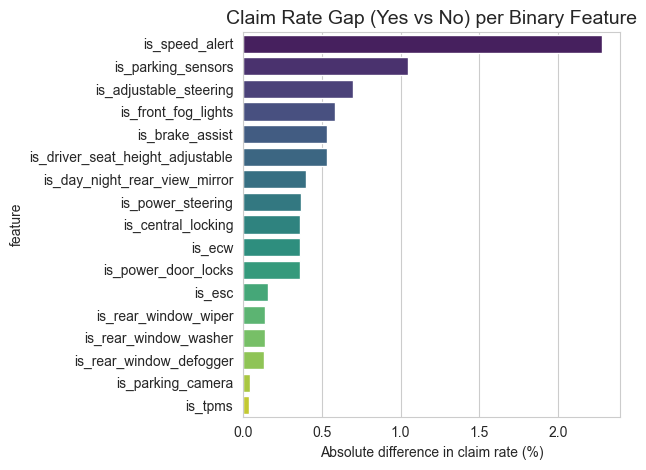

In [23]:
sns.barplot(data=gap_df, y= "feature",  x = "gap", palette = "viridis")
plt.title("Claim Rate Gap (Yes vs No) per Binary Feature", fontsize=14)
plt.xlabel("Absolute difference in claim rate (%)")
plt.tight_layout()
plt.show()

In [24]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
subscription_length,58592.0,6.111688,4.142790,0.0,2.1,5.7,10.4,14.0
vehicle_age,58592.0,1.388473,1.134413,0.0,0.4,1.2,2.2,20.0
customer_age,58592.0,44.823935,6.935604,35.0,39.0,44.0,49.0,75.0
region_density,58592.0,18826.858667,17660.174792,290.0,6112.0,8794.0,27003.0,73430.0
airbags,58592.0,3.137066,1.832641,1.0,2.0,2.0,6.0,6.0
displacement,58592.0,1162.355851,266.304786,796.0,796.0,1197.0,1493.0,1498.0
cylinder,58592.0,3.626963,0.483616,3.0,3.0,4.0,4.0,4.0
turning_radius,58592.0,4.852893,0.228061,4.5,4.6,4.8,5.0,5.2
length,58592.0,3850.476891,311.457119,3445.0,3445.0,3845.0,3995.0,4300.0
width,58592.0,1672.233667,112.089135,1475.0,1515.0,1735.0,1755.0,1811.0


In [25]:
df.groupby('claim_status')[num_cols].mean().T.round(2)

claim_status,0,1
subscription_length,6.03,7.36
vehicle_age,1.40,1.27
customer_age,44.78,45.41
region_density,18909.07,17623.82
airbags,3.14,3.16
displacement,1161.82,1170.18
cylinder,3.63,3.65
turning_radius,4.85,4.86
length,3849.95,3858.21
width,1671.94,1676.50


In [26]:
cat_to_explore = ["region_code", "model", "segment", "fuel_type", "transmission_type", "steering_type"]

for col in cat_to_explore:

    grp = df.groupby(col)["claim_status"].agg(["count", "mean"]).sort_values("count", ascending= False)

    grp["mean"] = (grp["mean"] * 100).round(2)

    print(f"------- {col} --------")

    print(grp.head(10))

------- region_code --------
             count  mean
region_code             
C8           13654  6.99
C2            7342  7.08
C5            6979  5.77
C3            6101  7.10
C14           3660  7.68
C13           3423  5.70
C10           3155  4.69
C9            2734  4.97
C7            2167  5.03
C12           1589  5.48
------- model --------
       count  mean
model             
M1     14948  6.14
M4     14018  6.43
M6     13776  6.82
M8      4173  5.85
M7      2940  6.84
M3      2373  5.39
M9      2114  6.29
M5      1598  7.26
M10     1209  6.04
M2      1080  7.41
------- segment --------
         count  mean
segment             
B2       18314  6.86
A        17321  6.04
C2       14018  6.43
B1        4173  5.85
C1        3557  6.41
Utility   1209  6.04
------- fuel_type --------
           count  mean
fuel_type             
Petrol     20532  6.64
CNG        20330  6.07
Diesel     17730  6.49
------- transmission_type --------
                   count  mean
transmission_type  

In [27]:
import warnings
warnings.filterwarnings("ignore")

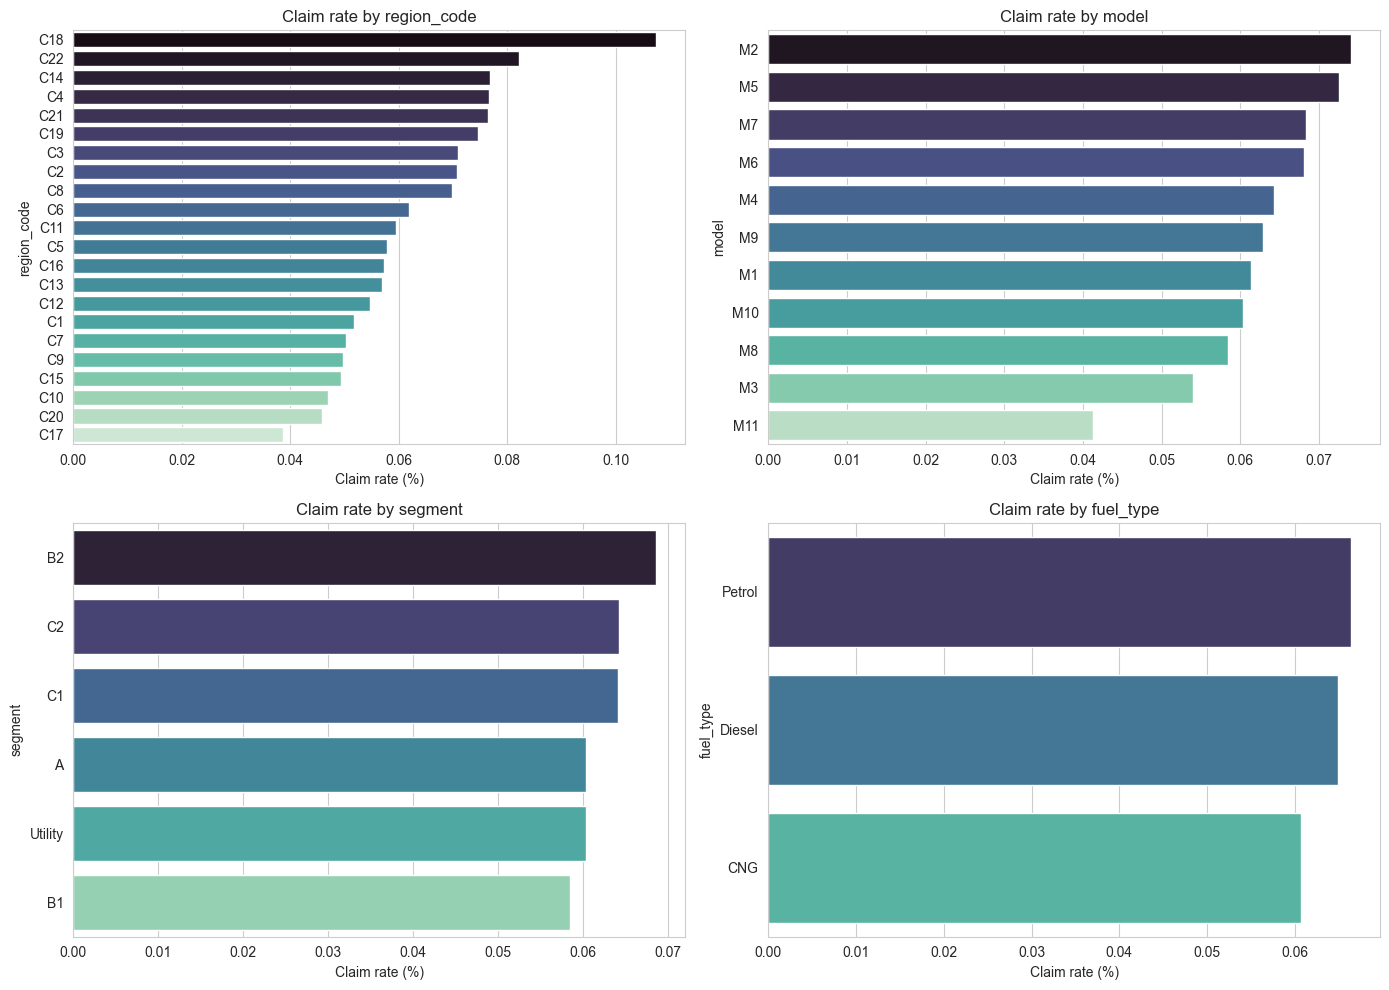

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, ["region_code", "model", "segment", "fuel_type"]):

    grp = df.groupby(col)["claim_status"].mean().sort_values(ascending=False)

    sns.barplot(x = grp.values, y = grp.index, ax = ax, palette = "mako")

    ax.set_title(f"Claim rate by {col}")

    ax.set_xlabel("Claim rate (%)")

plt.tight_layout()
plt.show()

In [29]:
corr_cols = num_cols + ["claim_status"]

corr = df[corr_cols].corr()



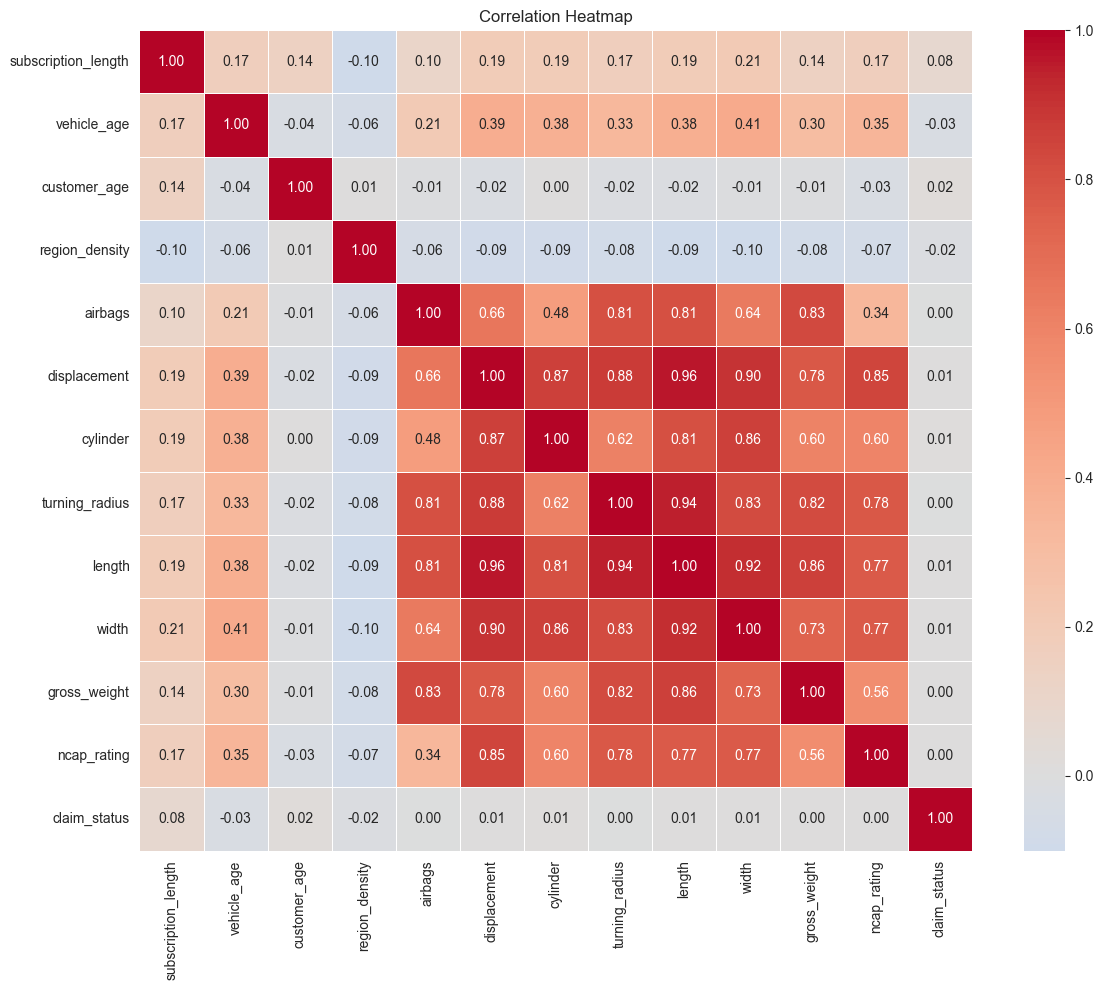

In [30]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt = ".2f", cmap = "coolwarm", center = 0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [31]:
for col in ["subscription_length", "vehicle_age", "customer_age"]:
    print(f"----- {col} -----")
    print(df[col].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99]))

----- subscription_length -----
count    58592.000000
mean         6.111688
std          4.142790
min          0.000000
1%           0.100000
5%           0.400000
25%          2.100000
50%          5.700000
75%         10.400000
95%         12.000000
99%         12.400000
max         14.000000
Name: subscription_length, dtype: float64
----- vehicle_age -----
count    58592.000000
mean         1.388473
std          1.134413
min          0.000000
1%           0.000000
5%           0.000000
25%          0.400000
50%          1.200000
75%          2.200000
95%          3.400000
99%          4.200000
max         20.000000
Name: vehicle_age, dtype: float64
----- customer_age -----
count    58592.000000
mean        44.823935
std          6.935604
min         35.000000
1%          35.000000
5%          35.000000
25%         39.000000
50%         44.000000
75%         49.000000
95%         58.000000
99%         63.000000
max         75.000000
Name: customer_age, dtype: float64


In [32]:
print(f" Vehicle Age > 10: ", (df["vehicle_age"] > 10).sum())

 Vehicle Age > 10:  6


In [33]:
(df["subscription_length"] == 0).sum()

np.int64(276)

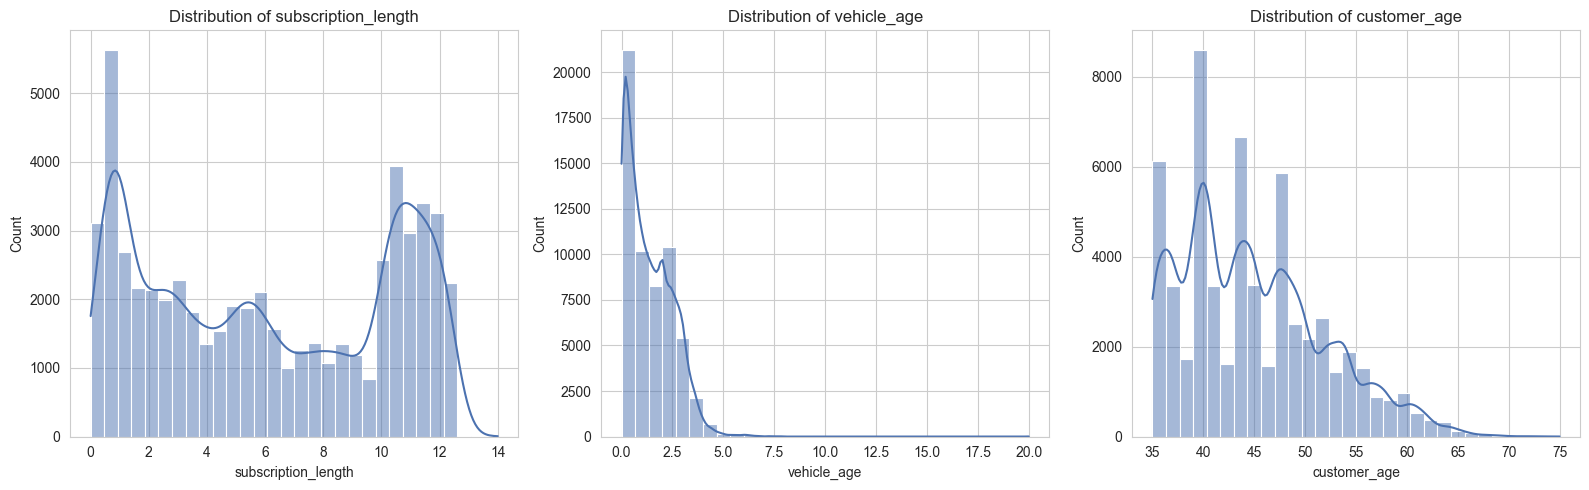

In [34]:
fig , axes = plt.subplots(1, 3, figsize = (16,5))

for ax, col in zip(axes.flat, ["subscription_length", "vehicle_age", "customer_age"]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color = "#4C72B0")
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()
    

In [35]:
df[["max_torque", "max_power"]]

,max_torque,max_power
0,250Nm@2750rpm,113.45bhp@4000rpm
1,200Nm@1750rpm,97.89bhp@3600rpm
2,250Nm@2750rpm,113.45bhp@4000rpm
3,60Nm@3500rpm,40.36bhp@6000rpm
4,200Nm@3000rpm,88.77bhp@4000rpm
...,...,...
58587,113Nm@4400rpm,88.50bhp@6000rpm
58588,250Nm@2750rpm,113.45bhp@4000rpm
58589,113Nm@4400rpm,88.50bhp@6000rpm
58590,113Nm@4400rpm,88.50bhp@6000rpm


In [36]:
torque_parsed = df["max_torque"].str.extract(r"([\d.]+)Nm@([\d.]+)rpm").astype(float)
torque_parsed

,0,1
0,250.0,2750.0
1,200.0,1750.0
2,250.0,2750.0
3,60.0,3500.0
4,200.0,3000.0
...,...,...
58587,113.0,4400.0
58588,250.0,2750.0
58589,113.0,4400.0
58590,113.0,4400.0


In [37]:
power_parsed = df["max_power"].str.extract(r"([\d.]+)bhp@([\d.]+)rpm").astype(float)
power_parsed

,0,1
0,113.45,4000.0
1,97.89,3600.0
2,113.45,4000.0
3,40.36,6000.0
4,88.77,4000.0
...,...,...
58587,88.50,6000.0
58588,113.45,4000.0
58589,88.50,6000.0
58590,88.50,6000.0


In [38]:
df["torque_Nm"] = torque_parsed[0]
df["torque_rpm"] = torque_parsed[1]
df["power_bhp"] = power_parsed[0]
df["power_rpm"] = power_parsed[1]

In [39]:
df

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status,torque_Nm,torque_rpm,power_bhp,power_rpm
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0,250.0,2750.0,113.45,4000.0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,97.89bhp@3600rpm,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.9,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0,200.0,1750.0,97.89,3600.0
2,POL007194,9.5,0.2,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0,250.0,2750.0,113.45,4000.0
3,POL018146,5.2,0.4,44,C10,73430,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,Power,4.6,3445,1515,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0,60.0,3500.0,40.36,6000.0
4,POL049011,10.1,1.0,56,C13,5410,B2,M5,Diesel,200Nm@3000rpm,88.77bhp@4000rpm,1.5 Turbocharged Revotorq,2,No,Yes,No,Yes,No,Drum,1497,4,Manual,Electric,5.0,3990,1755,1490,No,No,No,No,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0,200.0,3000.0,88.77,4000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,POL019269,10.6,2.6,48,C5,34738,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,Electric,4.8,3845,1735,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0,113.0,4400.0,88.50,6000.0
58588,POL001254,2.3,2.2,37,C3,4076,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0,250.0,2750.0,113.45,4000.0
58589,POL019859,6.6,2.2,35,C8,8794,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,Electric,4.8,3845,1735,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0,113.0,4400.0,88.50,6000.0
58590,POL014061,4.1,3.6,44,C8,8794,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,Electric,4.8,3845,1735,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0,113.0,4400.0,88.50,6000.0


In [40]:
torque_parsed.isna().any(axis=1).sum()

np.int64(0)

In [41]:
power_parsed.isna().any(axis=1).sum()

np.int64(0)

In [42]:
df.columns

Index(['policy_id', 'subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'segment', 'model', 'fuel_type',
       'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera',
       'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight',
       'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert',
       'ncap_rating', 'claim_status', 'torque_Nm', 'torque_rpm', 'power_bhp', 'power_rpm'],
      dtype='object')

In [43]:
drop_cols = [
    'policy_id', 'segment', 'engine_type',  'fuel_type', 'max_torque', 'max_power',
    'torque_Nm', 'torque_rpm', 'power_bhp', 'power_rpm',
    'displacement', 'cylinder', 'turning_radius', 'length', 'width',
    'gross_weight', 'ncap_rating', 'airbags', 'steering_type',
    'transmission_type', 'rear_brakes_type', 'is_esc', 'is_adjustable_steering',
    'region_code',
    'is_tpms', 'is_parking_camera', 'is_rear_window_wiper', 'is_rear_window_washer',
    'is_rear_window_defogger', 'is_central_locking', 'is_power_door_locks', 'is_ecw'
]

In [44]:
df_clean = df.drop(columns=drop_cols)

In [45]:
df_clean.columns

Index(['subscription_length', 'vehicle_age', 'customer_age', 'region_density', 'model', 'is_parking_sensors', 'is_front_fog_lights',
       'is_brake_assist', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_speed_alert',
       'claim_status'],
      dtype='object')

In [46]:
df_clean.shape

(58592, 13)

In [47]:
binary_final = ['is_parking_sensors', 'is_front_fog_lights', 'is_brake_assist',
                'is_power_steering', 'is_driver_seat_height_adjustable',
                'is_day_night_rear_view_mirror', 'is_speed_alert']

for col in binary_final:
    df_clean[col] = df_clean[col].map({"Yes": 1, "No": 0})

In [48]:
df_clean

,subscription_length,vehicle_age,customer_age,region_density,model,is_parking_sensors,is_front_fog_lights,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert,claim_status
0,9.3,1.2,41,8794,M4,1,1,1,1,1,0,1,0
1,8.2,1.8,35,27003,M9,1,1,0,1,1,1,1,0
2,9.5,0.2,44,8794,M4,1,1,1,1,1,0,1,0
3,5.2,0.4,44,73430,M1,1,0,0,1,0,0,1,0
4,10.1,1.0,56,5410,M5,1,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,10.6,2.6,48,34738,M6,1,1,1,1,1,1,1,0
58588,2.3,2.2,37,4076,M4,1,1,1,1,1,0,1,0
58589,6.6,2.2,35,8794,M6,1,1,1,1,1,1,1,0
58590,4.1,3.6,44,8794,M6,1,1,1,1,1,1,1,0


In [49]:
df_model = pd.get_dummies(df_clean, columns=["model"],  drop_first= True)
df_model

,subscription_length,vehicle_age,customer_age,region_density,is_parking_sensors,is_front_fog_lights,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert,claim_status,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9
0,9.3,1.2,41,8794,1,1,1,1,1,0,1,0,False,False,False,False,True,False,False,False,False,False
1,8.2,1.8,35,27003,1,1,0,1,1,1,1,0,False,False,False,False,False,False,False,False,False,True
2,9.5,0.2,44,8794,1,1,1,1,1,0,1,0,False,False,False,False,True,False,False,False,False,False
3,5.2,0.4,44,73430,1,0,0,1,0,0,1,0,False,False,False,False,False,False,False,False,False,False
4,10.1,1.0,56,5410,1,0,0,1,0,0,1,0,False,False,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,10.6,2.6,48,34738,1,1,1,1,1,1,1,0,False,False,False,False,False,False,True,False,False,False
58588,2.3,2.2,37,4076,1,1,1,1,1,0,1,0,False,False,False,False,True,False,False,False,False,False
58589,6.6,2.2,35,8794,1,1,1,1,1,1,1,0,False,False,False,False,False,False,True,False,False,False
58590,4.1,3.6,44,8794,1,1,1,1,1,1,1,0,False,False,False,False,False,False,True,False,False,False


In [50]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns= ["claim_status"])
y = df["claim_status"]
                  

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify= y)

In [52]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()

scale_pos_weight = neg_count / pos_count 

scale_pos_weight

# This onfirms our roughly 14:1 imbalance and gives XG boost a weight of about 
# 14 to apply to every positive claim example during training
# So it stops ignoring the minority class

np.float64(14.634756504336224)

In [53]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [54]:
dt = DecisionTreeClassifier(
    max_depth = 4, class_weight = "balanced"
)

dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [55]:
rf = RandomForestClassifier(
    n_estimators = 300, class_weight = "balanced", n_jobs = -1)

rf.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
xgb = XGBClassifier(
    n_estimators = 300, max_depth = 4, learning_rate = 0.05,
    scale_pos_weight = scale_pos_weight, eval_metric = "logloss",
    n_jobs = -1
)



In [57]:
xgb.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [58]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [59]:
models = [("Decision Tree", dt), ("Random Forest", rf), ("XGBoost", xgb)]

# This is a list of tuples

In [60]:
auc_scores = {}

for name, model in models:
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probs)
    auc_scores[name] = auc

    print(f"-----{name}-----")
    print(classification_report(y_test, preds))
    print("ROC-AUC", round(auc, 4))

-----Decision Tree-----
              precision    recall  f1-score   support

           0       0.96      0.60      0.74     10969
           1       0.09      0.59      0.16       750

    accuracy                           0.60     11719
   macro avg       0.52      0.60      0.45     11719
weighted avg       0.90      0.60      0.70     11719

ROC-AUC 0.627
-----Random Forest-----
              precision    recall  f1-score   support

           0       0.94      0.99      0.96     10969
           1       0.10      0.01      0.02       750

    accuracy                           0.93     11719
   macro avg       0.52      0.50      0.49     11719
weighted avg       0.88      0.93      0.90     11719

ROC-AUC 0.5746
-----XGBoost-----
              precision    recall  f1-score   support

           0       0.96      0.58      0.72     10969
           1       0.09      0.63      0.16       750

    accuracy                           0.58     11719
   macro avg       0.53      0.61

In [61]:
best_name = max(auc_scores, key = auc_scores.get)
best_model = dict(models)[best_name]

In [62]:
best_name

'XGBoost'

In [63]:
best_model

# You want to find the actual model object corresponding to

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [64]:
importances = pd.Series(best_model.feature_importances_, index = X_train.columns).sort_values(ascending=False)
importances

is_driver_seat_height_adjustable    0.124319
is_front_fog_lights                 0.121688
subscription_length                 0.091337
vehicle_age                         0.090181
is_brake_assist                     0.062817
model_M8                            0.053717
is_day_night_rear_view_mirror       0.050937
is_parking_sensors                  0.049045
model_M6                            0.046589
model_M5                            0.041098
region_density                      0.038362
model_M7                            0.037857
model_M4                            0.034090
model_M9                            0.033774
is_speed_alert                      0.033758
customer_age                        0.032364
is_power_steering                   0.030283
model_M2                            0.027784
model_M10                           0.000000
model_M11                           0.000000
model_M3                            0.000000
dtype: float32

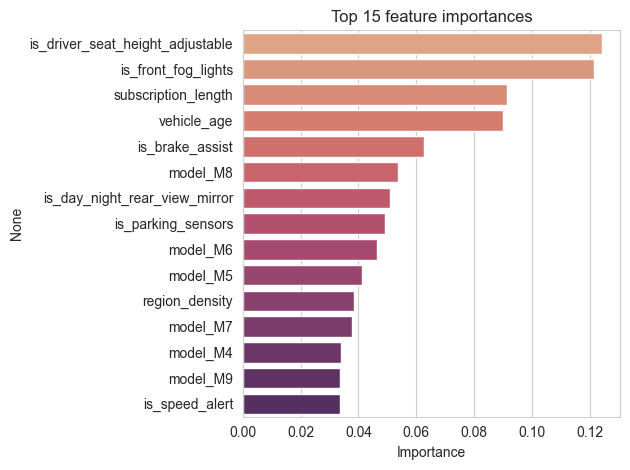

In [66]:
sns.barplot(x = importances.values[:15], y = importances.index[:15], palette = "flare")

plt.title("Top 15 feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [68]:
import joblib

joblib.dump(best_model, "claim_model.pkl")
joblib.dump(X_train.columns.tolist(), "model_columns.pkl")
joblib.dump(sorted(df_clean["model"].unique().tolist()), "model_options.pkl")

['model_options.pkl']